# Testbed — FORCE connectivity for sequences with a pulsed parameter

**Question.** When one control of the sequence (width, speed, amplitude, or the network's E − I drive) is pulsed
during the training snippet, how does the learned connectivity change? Do the neurons active during the pulse get
different connectivity profiles from the neurons before and after?

**Protocol** (`seqnet.experiments.pulsed`):
- Every network (realization) trains on the same snippet: one pass of the bump around the ring from t = 0, with the
  pulse at the middle (4.25 s). Realizations differ only in J0 and noise.
- Matrices are therefore averaged neuron by neuron, and each neuron is active exactly once.
- Each pulsed condition is compared with its unpulsed **control**, using the same neuron groups. This separates the
  pulse's effect from any effect of the neurons' position in the snippet.
- Settings: Braun's FORCE settings, except for the fixed one-pass snippet and the reduced realization and iteration
  counts in the config.

**Profiles** (`seqnet.analysis.neuron_profiles`):
- **Incoming** profile of neuron n: P_in[n, d] = W[n, n + d], the weight onto n from the neuron d steps later in the
  sequence. Negative d means input from earlier neurons (feed-forward drive).
- **Outgoing** profile: P_out[n, d] = W[n − d, n].
- Both average over n to Braun's mean profile cp_d (eq. 11).
- **Groups:** neurons at offsets *before* / *at* / *after* from the **pulse neuron**, the bump centre at the pulse
  peak.
- **Display:** neurons are shown in snippet order, with the pulse neuron at the centre.

Settings in `configs/pulsed/pulsed_testbed.yaml`.

**Panels:**
- A: targets and pulses
- B: training and test responses
- C: connectivity matrices
- D: mean connectivity profile
- E: profiles along the sequence
- F: group profiles (before / at / after)
- G: profile features along the sequence
- H: the profile every 20 neurons (overlay and ridgeline)
- I: harmonic decomposition and the speed it implies
- J: variance across neurons per offset d
- K: stretch, gain and the main shapes of change
- L: interactive explorer (live kernel)
- M: summary and checks

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet import conventions as cv
from seqnet.analysis import neuron_profiles as npf
from seqnet.experiments import pulsed as pz
from seqnet.sequences import build_sequence

style()
fig = Figure("pulsed", "pulsed_testbed")
cfg = fig.config()
N, an, tr = cfg["N"], cfg["analysis"], cfg["training"]
t_p = cfg["pulse"]["t_peak"]
conds = {}
for name, c in cfg["conditions"].items():
    pulse = None
    if "param" in c:
        pulse = pz.Pulse(c["param"], c["height"], c.get("t_peak", t_p), c.get("width", cfg["pulse"]["width"]))
    spec = pz.pulsed_spec(cfg["bases"][c["base"]], pulse)
    seq = build_sequence(spec)
    conds[name] = {"spec": spec, "pulse": pulse, "control": c.get("control"), "seq": seq,
                   "n_p": pz.pulse_neuron(seq, t_p), "T_snip": pz.pass_duration(seq, tr["passes"])}
pulsed = [n for n, c in conds.items() if c["pulse"] is not None]


def order(name):
    # neurons in snippet order with the pulse neuron (of ``name``) at the centre
    return (int(round(conds[name]["n_p"])) + np.arange(N) - N // 2) % N


groups_c = {g: N // 2 + np.arange(lo, hi + 1) for g, (lo, hi) in an["groups"].items()}  # groups in display order
{n: f"snippet {c['T_snip']:.2f} s, pulse neuron {c['n_p']:.0f}, control: {c['control']}" for n, c in conds.items()}

{'bump': 'snippet 8.50 s, pulse neuron 250, control: None',
 'narrow': 'snippet 8.50 s, pulse neuron 250, control: bump',
 'wide': 'snippet 8.50 s, pulse neuron 250, control: bump',
 'fast': 'snippet 6.62 s, pulse neuron 306, control: bump',
 'slow': 'snippet 9.25 s, pulse neuron 228, control: bump',
 'dim': 'snippet 8.50 s, pulse neuron 250, control: bump',
 'network': 'snippet 8.50 s, pulse neuron 24, control: None',
 'net_inhibit': 'snippet 8.53 s, pulse neuron 23, control: network',
 'net_excite': 'snippet 8.46 s, pulse neuron 25, control: network'}

## Panel A — training targets and pulses

One pass of each sequence.
- **White line:** the pulse in the control, as height above its baseline.
- **Shaded bands:** the neuron groups.
- Speed pulses change the snippet length (one pass): *fast* is shorter, *slow* longer.

In [2]:
dt_r = 0.05
out = {}
for name, c in conds.items():
    t = np.arange(0, c["T_snip"], dt_r)
    out[f"{name}_t"] = t
    out[f"{name}_R"] = c["seq"].rates(t)[order(name)].astype(np.float32)
    p = c["pulse"]
    out[f"{name}_pulse"] = np.zeros_like(t) if p is None else p.height * np.exp(-((t - p.t_peak) ** 2) / (2 * p.width**2))
fig.save("A_targets", params=cfg["conditions"], **out);

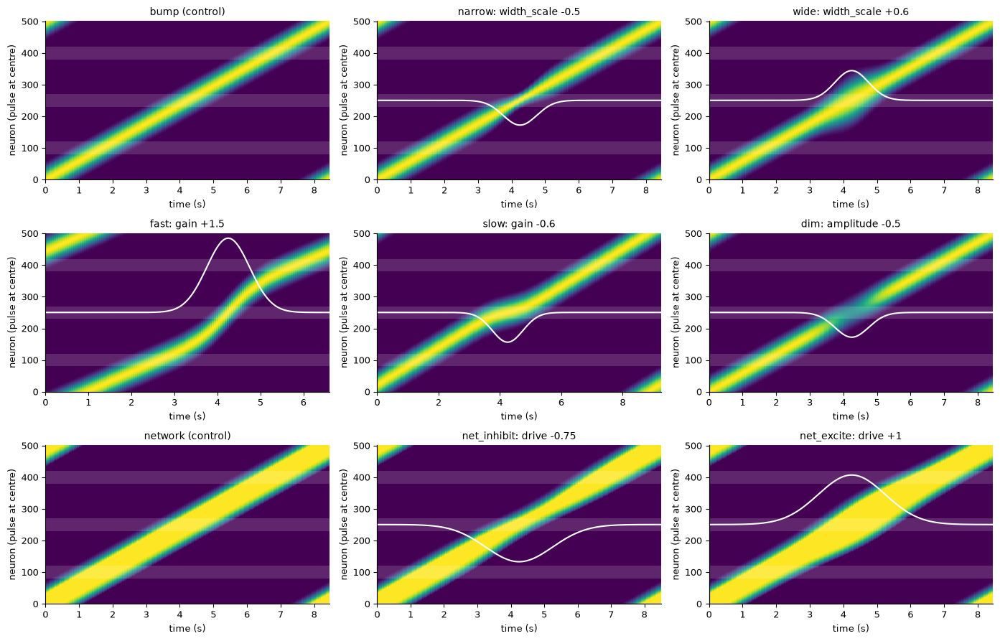

In [3]:
d = fig.load("A_targets")
names = list(conds)
nc = 3
F, axs = plt.subplots(int(np.ceil(len(names) / nc)), nc, figsize=(14, 3 * np.ceil(len(names) / nc)), squeeze=False)
for ax, name in zip(axs.flat, names):
    t = d[f"{name}_t"]
    ax.imshow(d[f"{name}_R"], aspect="auto", origin="lower", extent=[0, t[-1], 0, N], vmin=0, vmax=1,
              interpolation="nearest")
    for g, idx in groups_c.items():
        ax.axhspan(idx[0], idx[-1], color="w", alpha=0.15, lw=0)
    if conds[name]["pulse"] is not None:
        tw = ax.twinx(); tw.plot(t, d[f"{name}_pulse"], "w", lw=1.5); tw.set_ylim(-1.6, 1.6); tw.set_yticks([])
        ax.set_title(f"{name}: {conds[name]['pulse'].param} {conds[name]['pulse'].height:+g}")
    else:
        ax.set_title(f"{name} (control)")
    ax.set_xlabel("time (s)"); ax.set_ylabel("neuron (pulse at centre)")
for ax in axs.flat[len(names):]:
    ax.axis("off")
F.tight_layout()
fig.savefig("A_targets", F); plt.show()

## Panel B — training, and the test response of realization 1

FORCE is trained (or the cached run loaded, from `results/pulsed/runs/`), then for each condition:
- **Top:** the target over the snippet.
- **Middle:** the response of realization 1 in the last test iteration.
- **Bottom:** the target–response correlation over the training and test iterations (mean ± SD over realizations).

In [4]:
runs = {}
for name, c in conds.items():
    fc = pz.condition_config(c["spec"], tr["n_train"], tr["n_test"], tr["passes"])
    runs[name] = pz.run(name, fc, tr["n_realizations"])
W = {name: np.stack([r.W(i) for i in range(tr["n_realizations"])]) for name, r in runs.items()}
out = {}
for name, r in runs.items():
    o = order(name)
    out[f"{name}_corr"] = r.summary["corr"]
    out[f"{name}_target"] = r.summary["f_target0"][o]
    out[f"{name}_resp"] = r.summary["R_test0"][o]
fig.save("B_training", params=tr, **out)
{name: round(float(r.summary["corr"][:, -tr["n_test"]:].mean()), 3) for name, r in runs.items()}

{'bump': 0.847,
 'narrow': 0.828,
 'wide': 0.862,
 'fast': 0.794,
 'slow': 0.879,
 'dim': 0.843,
 'network': 0.912,
 'net_inhibit': 0.905,
 'net_excite': 0.917}

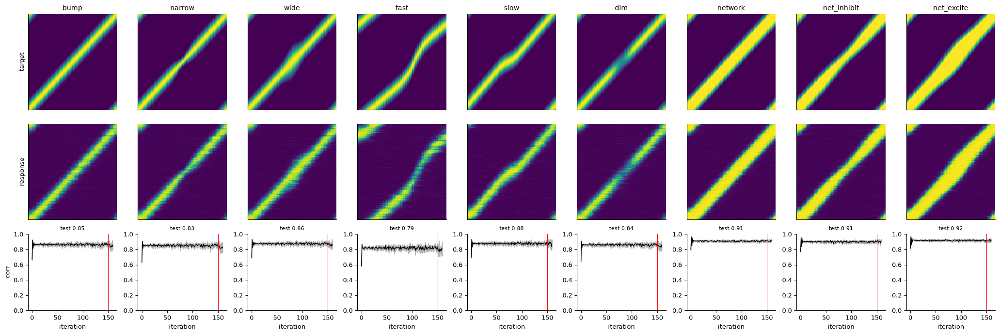

In [5]:
d = fig.load("B_training")
F, axs = plt.subplots(3, len(names), figsize=(2.3 * len(names), 7), gridspec_kw={"height_ratios": [1, 1, 0.8]})
for j, name in enumerate(names):
    for i, key in enumerate(("target", "resp")):
        axs[i, j].imshow(d[f"{name}_{key}"], aspect="auto", origin="lower", vmin=0, vmax=1, interpolation="nearest")
        axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
    axs[0, j].set_title(name)
    c = d[f"{name}_corr"]
    it = np.arange(c.shape[1])
    axs[2, j].plot(it, c.mean(0), "k", lw=1); axs[2, j].fill_between(it, c.mean(0) - c.std(0), c.mean(0) + c.std(0), color="0.7")
    axs[2, j].axvline(tr["n_train"], color="r", lw=0.8); axs[2, j].set_ylim(0, 1)
    axs[2, j].set_title(f"test {c[:, -tr['n_test']:].mean():.2f}", fontsize=8); axs[2, j].set_xlabel("iteration")
axs[0, 0].set_ylabel("target"); axs[1, 0].set_ylabel("response"); axs[2, 0].set_ylabel("corr")
F.tight_layout()
fig.savefig("B_training", F); plt.show()

## Panel C — connectivity matrices

The mean matrix over realizations, in snippet order with the pulse neuron at the centre.
- **Top:** the full matrix.
- **Bottom:** a zoom of ± `zoom` neurons around the pulse neuron, with the groups marked.
- **Diagonals:** the self-weights (d = 0) sit on the main diagonal; incoming profiles run along each row.

In [6]:
out = {}
for name in names:
    o = order(name)
    out[name] = W[name].mean(0)[np.ix_(o, o)].astype(np.float32)
fig.save("C_matrices", params={"clip": an["clip"], "zoom": an["zoom"]}, **out);

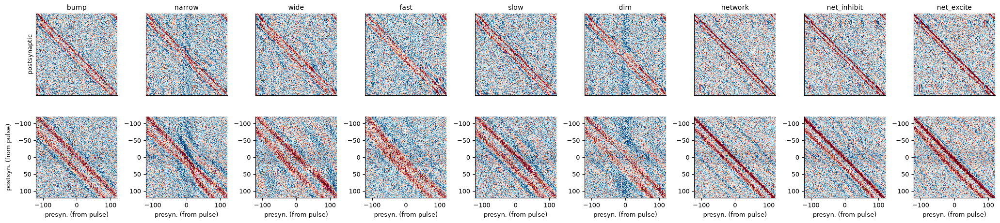

In [7]:
d = fig.load("C_matrices")
z, cl = an["zoom"], an["clip"]
F, axs = plt.subplots(2, len(names), figsize=(2.3 * len(names), 5))
for j, name in enumerate(names):
    M = d[name]
    axs[0, j].imshow(M, cmap="RdBu_r", vmin=-cl, vmax=cl, interpolation="nearest")
    sl = slice(N // 2 - z, N // 2 + z + 1)
    axs[1, j].imshow(M[sl, sl], cmap="RdBu_r", vmin=-cl, vmax=cl, interpolation="nearest",
                     extent=[-z - 0.5, z + 0.5, z + 0.5, -z - 0.5])
    for g, idx in groups_c.items():
        lo, hi = idx[0] - N // 2, idx[-1] - N // 2
        if -z <= lo and hi <= z:
            axs[1, j].axhspan(lo, hi, color="k", alpha=0.08, lw=0)
    axs[0, j].set_title(name); axs[0, j].set_xticks([]); axs[0, j].set_yticks([])
    axs[1, j].set_xlabel("presyn. (from pulse)")
axs[0, 0].set_ylabel("postsynaptic"); axs[1, 0].set_ylabel("postsyn. (from pulse)")
F.tight_layout()
fig.savefig("C_matrices", F); plt.show()

## Panel D — mean connectivity profile

Braun's profile cp_d of the mean matrix: the average of all neurons' incoming profiles. Each pulsed condition (colour)
is shown with its control (grey), mean ± SEM over realizations. The self-weight d = 0 is replaced by the mean of its
neighbours for display; its value is printed. A pulse touches only part of the sequence, so its trace in this average
is diluted; Panels E–G resolve it by neuron.

In [8]:
out = {}
for name in names:
    dd, cp = cv.centred_profile(cv.profile_from_matrix(W[name]))  # (realizations, N)
    keep = np.abs(dd) <= an["d_max"]
    out[f"{name}_cp"] = cp[:, keep]
out["d"] = dd[keep]
fig.save("D_mean_profile", params={"d_max": an["d_max"]}, **out);

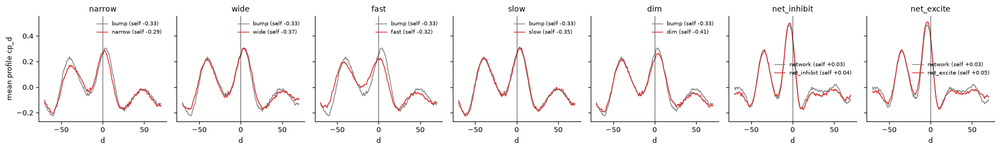

In [9]:
d = fig.load("D_mean_profile")
sem = lambda x: x.std(0) / np.sqrt(x.shape[0])
F, axs = plt.subplots(1, len(pulsed), figsize=(2.6 * len(pulsed), 2.8), sharey=True)
for ax, name in zip(np.atleast_1d(axs), pulsed):
    for key, col in ((conds[name]["control"], "0.5"), (name, "C3")):
        cp = d[f"{key}_cp"]
        m = npf.remove_self(d["d"], cp.mean(0))
        ax.plot(d["d"], m, color=col, lw=1, label=f"{key} (self {cp.mean(0)[d['d'] == 0][0]:+.2f})")
        ax.fill_between(d["d"], m - sem(cp), m + sem(cp), color=col, alpha=0.3, lw=0)
    ax.axvline(0, color="k", lw=0.5); ax.set_title(name); ax.set_xlabel("d"); ax.legend(frameon=False, fontsize=7)
np.atleast_1d(axs)[0].set_ylabel("mean profile cp_d")
F.tight_layout()
fig.savefig("D_mean_profile", F); plt.show()

## Panel E — profiles along the sequence

Each row is one neuron's incoming profile (mean over realizations, smoothed over `smooth` neighbouring neurons), in
snippet order with the pulse neuron at the centre (dashed). Columns: the pulsed condition, its control on the same
neurons, and the difference. In a translation-invariant sequence every row would be the same profile. The difference
map shows where along the sequence, and at which offsets d, the pulse changes the connectivity.

In [10]:
P = {}
for name in names:
    _, P[name] = npf.window(npf.local_profiles(W[name], "in"), an["d_max"])  # (realizations, N, D)
dwin = np.arange(-an["d_max"], an["d_max"] + 1)
out = {"d": dwin}
for name in pulsed:
    o = order(name)
    m = npf.smooth_neurons(npf.remove_self(dwin, P[name].mean(0)[o]), an["smooth"])
    mc = npf.smooth_neurons(npf.remove_self(dwin, P[conds[name]["control"]].mean(0)[o]), an["smooth"])
    out[f"{name}_map"], out[f"{name}_ctl"] = m.astype(np.float32), mc.astype(np.float32)
fig.save("E_along_sequence", params={"smooth": an["smooth"], "direction": "in"}, **out);

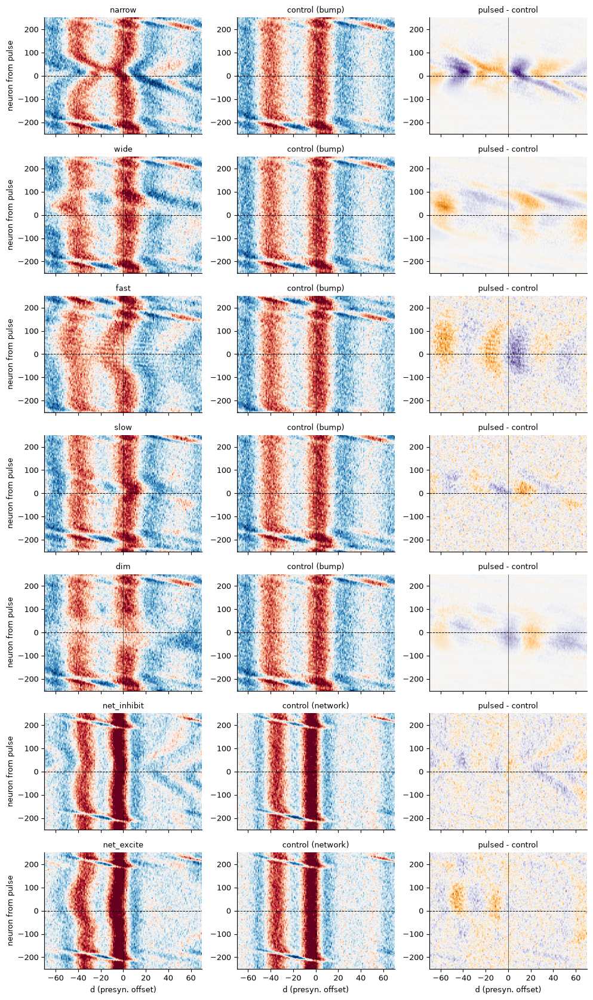

In [11]:
d = fig.load("E_along_sequence")
dl = max(np.abs(d[f"{n}_map"] - d[f"{n}_ctl"]).max() for n in pulsed)
F, axs = plt.subplots(len(pulsed), 3, figsize=(10, 2.4 * len(pulsed)), sharex=True)
ext = [d["d"][0], d["d"][-1], -N // 2, N - N // 2]
for i, name in enumerate(pulsed):
    for j, (img, lab, cmap, v) in enumerate([(d[f"{name}_map"], name, "RdBu_r", an["clip"]),
                                             (d[f"{name}_ctl"], f"control ({conds[name]['control']})", "RdBu_r", an["clip"]),
                                             (d[f"{name}_map"] - d[f"{name}_ctl"], "pulsed - control", "PuOr_r", dl)]):
        ax = axs[i, j]
        ax.imshow(img, aspect="auto", origin="lower", cmap=cmap, vmin=-v, vmax=v, extent=ext, interpolation="nearest")
        ax.axhline(0, color="k", ls="--", lw=0.7); ax.axvline(0, color="k", lw=0.4)
        ax.set_title(lab, fontsize=9)
    axs[i, 0].set_ylabel("neuron from pulse")
for ax in axs[-1]:
    ax.set_xlabel("d (presyn. offset)")
F.tight_layout()
fig.savefig("E_along_sequence", F); plt.show()

## Panel F — neurons before, at and after the pulse

The mean profile of each neuron group, for both directions (incoming above, outgoing below). Colour: the pulsed
condition. Grey: its control on the same neurons. Bands: SEM over realizations. Self-weight replaced by its
neighbours' mean.
- **Last column:** pulsed − control for each group. If the pulse's effect is local, only the *at* group moves.

In [12]:
out = {"d": dwin}
for direction in an["direction"]:
    Pd = {name: npf.window(npf.local_profiles(W[name], direction), an["d_max"])[1] for name in names}
    for name in pulsed:
        groups = npf.neuron_groups(conds[name]["n_p"], N, an["groups"])
        for key, src in (("p", name), ("c", conds[name]["control"])):
            for g, prof in npf.group_profiles(Pd[src], groups).items():  # (realizations, D)
                out[f"{direction}_{name}_{key}_{g}"] = prof
fig.save("F_groups", params={"groups": an["groups"], "direction": an["direction"]}, **out);

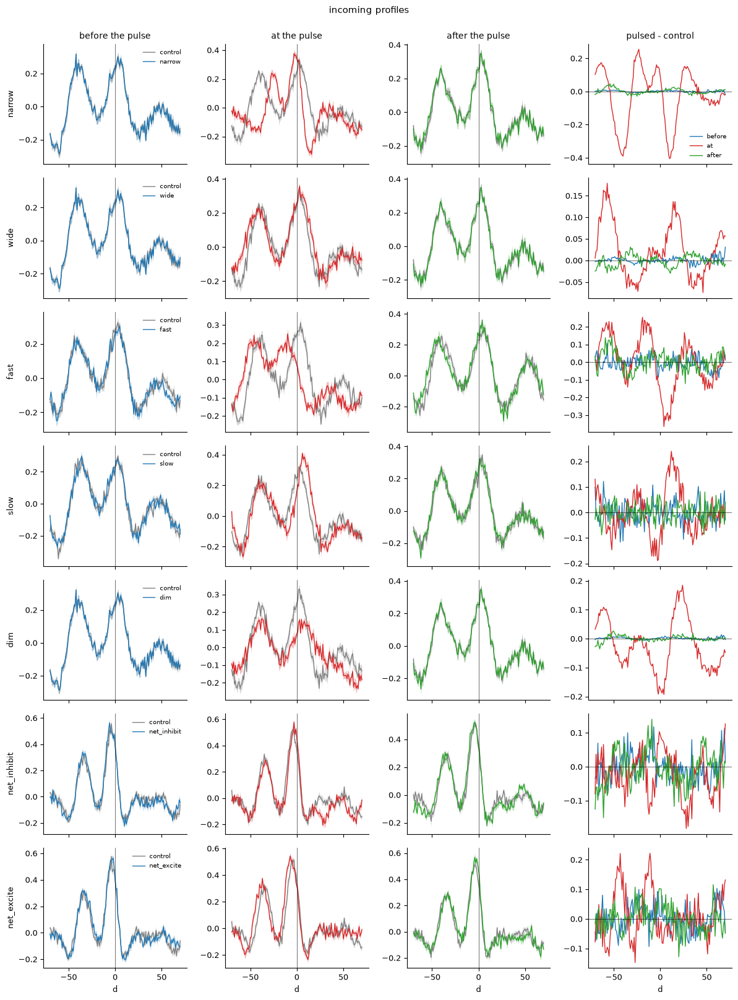

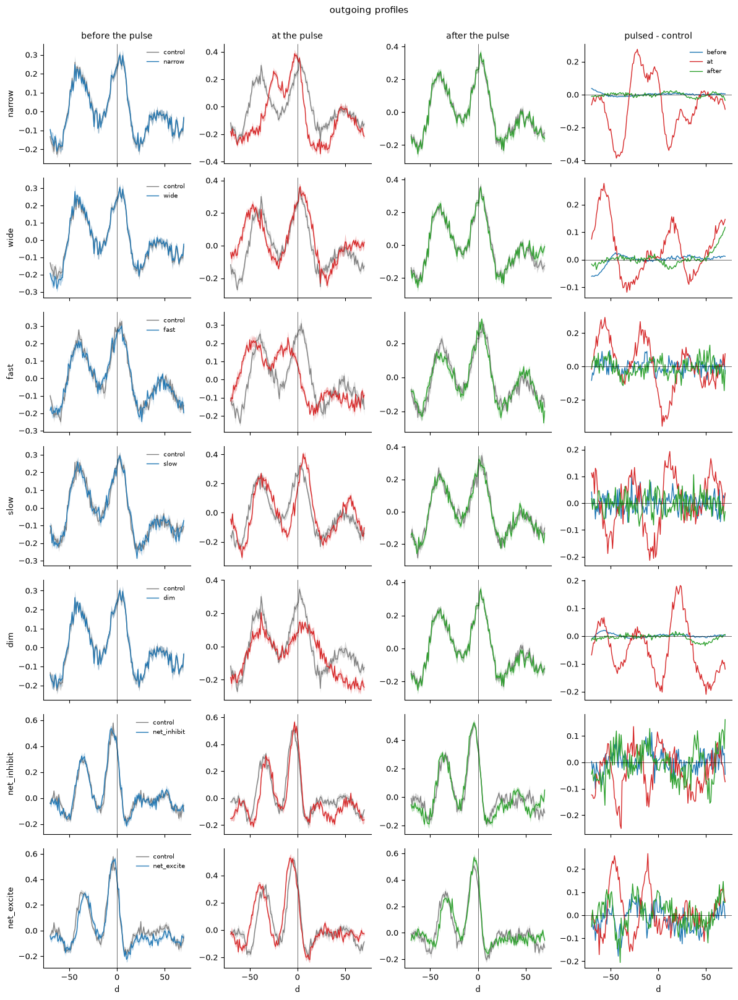

In [13]:
d = fig.load("F_groups")
gnames = list(an["groups"])
gcol = {"before": "C0", "at": "C3", "after": "C2"}
for direction in an["direction"]:
    F, axs = plt.subplots(len(pulsed), len(gnames) + 1, figsize=(3 * (len(gnames) + 1), 2.3 * len(pulsed)),
                          sharex=True, squeeze=False)
    for i, name in enumerate(pulsed):
        for j, g in enumerate(gnames):
            ax = axs[i, j]
            for key, col, lab in (("c", "0.5", "control"), ("p", gcol.get(g, "C3"), name)):
                x = npf.remove_self(d["d"], d[f"{direction}_{name}_{key}_{g}"])
                m, s = x.mean(0), sem(x)
                ax.plot(d["d"], m, color=col, lw=1, label=lab); ax.fill_between(d["d"], m - s, m + s, color=col, alpha=0.3, lw=0)
            ax.axvline(0, color="k", lw=0.4)
            if i == 0:
                ax.set_title(f"{g} the pulse")
            if j == 0:
                ax.set_ylabel(name)
        ax = axs[i, -1]
        for g in gnames:
            diff = npf.remove_self(d["d"], d[f"{direction}_{name}_p_{g}"] - d[f"{direction}_{name}_c_{g}"])
            ax.plot(d["d"], diff.mean(0), color=gcol.get(g, "k"), lw=1, label=g)
        ax.axhline(0, color="k", lw=0.4)
        if i == 0:
            ax.set_title("pulsed - control"); ax.legend(frameon=False, fontsize=7)
        axs[i, 0].legend(frameon=False, fontsize=7)
    for ax in axs[-1]:
        ax.set_xlabel("d")
    F.suptitle(f"{direction}coming profiles" if direction == "in" else "outgoing profiles", y=1.0)
    F.tight_layout()
    fig.savefig(f"F_groups_{direction}", F); plt.show()

## Panel G — profile features along the sequence

Features of each neuron's incoming profile (`neuron_profiles.profile_summary`; mean over realizations, smoothed over
neurons), plotted against sequence position relative to the pulse neuron.
- **self:** the self-weight.
- **peak / trough:** the largest and most negative weights at d ≠ 0.
- **asymmetry:** (Σ_{d>0} − Σ_{d<0}) / Σ|·|. Negative means input mainly from earlier neurons, i.e. feed-forward.

Colour: pulsed condition. Grey: control. Shading: the groups.

In [14]:
feats = ("self", "peak", "trough", "asymmetry")
out = {"n": np.arange(N) - N // 2}
for name in pulsed:
    o = order(name)
    for key, src in (("p", name), ("c", conds[name]["control"])):
        s = npf.profile_summary(dwin, npf.smooth_neurons(P[src].mean(0)[o], an["smooth"]))
        for f in feats:
            out[f"{name}_{key}_{f}"] = s[f]
fig.save("G_features", params={"features": feats, "smooth": an["smooth"]}, **out);

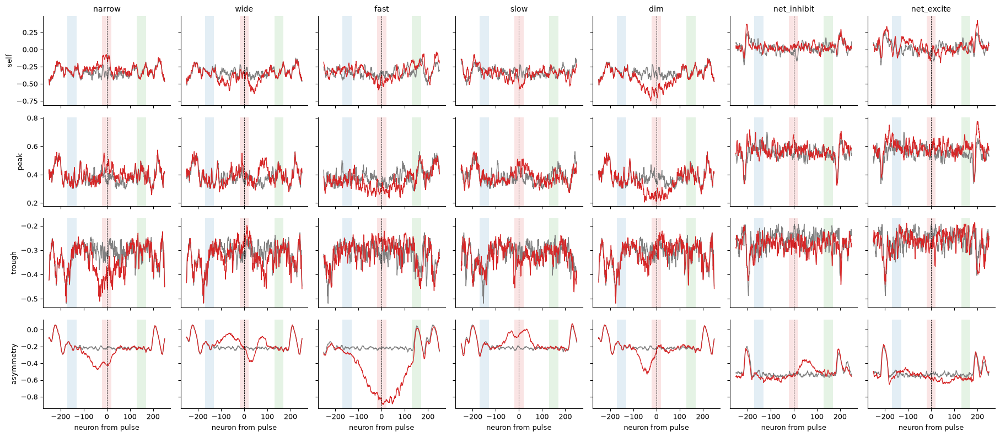

In [15]:
d = fig.load("G_features")
F, axs = plt.subplots(len(feats), len(pulsed), figsize=(2.6 * len(pulsed), 2.0 * len(feats)), sharex=True, sharey="row")
for j, name in enumerate(pulsed):
    for i, f in enumerate(feats):
        ax = axs[i, j]
        for g, idx in groups_c.items():
            ax.axvspan(idx[0] - N // 2, idx[-1] - N // 2, color=gcol.get(g, "k"), alpha=0.12, lw=0)
        ax.plot(d["n"], d[f"{name}_c_{f}"], color="0.5", lw=1)
        ax.plot(d["n"], d[f"{name}_p_{f}"], color="C3", lw=1)
        ax.axvline(0, color="k", ls="--", lw=0.6)
        if i == 0:
            ax.set_title(name)
        if j == 0:
            ax.set_ylabel(f)
for ax in axs[-1]:
    ax.set_xlabel("neuron from pulse")
F.tight_layout()
fig.savefig("G_features", F); plt.show()

## Panel H — the profile every 20 neurons

Incoming profiles averaged over consecutive bins of `bin` neurons (realization mean; self-weight replaced). Only the
interior of the snippet is shown, `edge` neurons away from its ends. The bin holding the pulse neuron is black.
- **Top:** all bins overlaid and coloured by position, with the control's mean profile dashed.
- **Bottom:** the same bins stacked as a ridgeline (earliest at the bottom), each over the control's profile for the
  same neurons (grey).

Where the coloured trace leaves the grey one, the pulse has changed that neuron's connectivity.

In [16]:
bw, edge = an["bin"], an["edge"]
out = {"d": dwin}
for name in pulsed:
    o = order(name)
    for key, src in (("p", name), ("c", conds[name]["control"])):
        B, centres = npf.binned_profiles(npf.remove_self(dwin, P[src].mean(0)[o]), bw)
        out[f"{name}_{key}"] = B
pos_bins = centres - N // 2  # bin centres relative to the pulse neuron
out["positions"], out["inner"] = pos_bins, np.abs(pos_bins) <= N // 2 - edge
fig.save("H_binned_profiles", params={"bin": bw, "edge": edge}, **out);

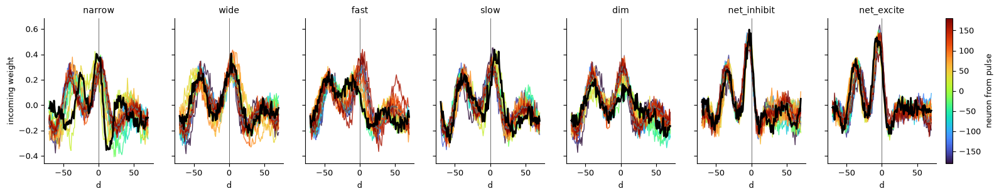

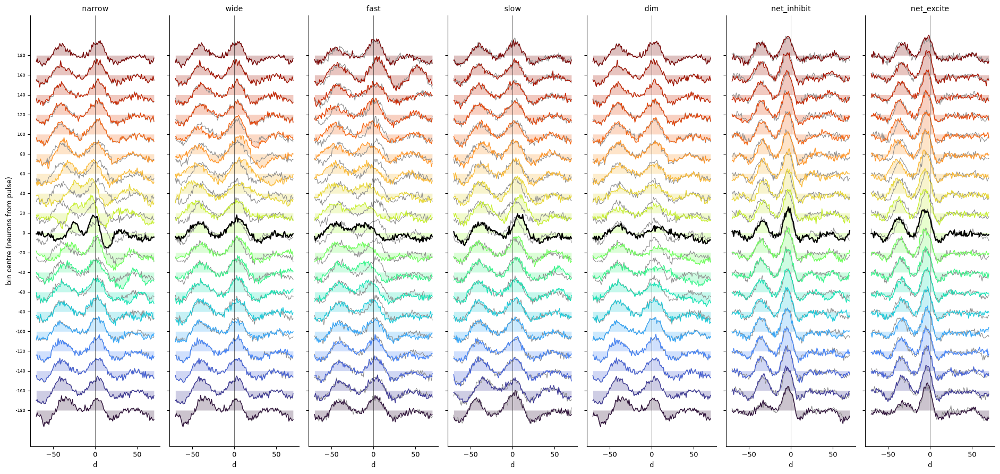

In [17]:
from seqnet.plotting import profiles as pp

d = fig.load("H_binned_profiles")
inner, pos = d["inner"], d["positions"]
F, axs = plt.subplots(1, len(pulsed), figsize=(2.7 * len(pulsed), 3), sharey=True)
for ax, name in zip(axs, pulsed):
    sm = pp.overlay(ax, d["d"], d[f"{name}_p"][inner], pos[inner], pulse=0.0, control=d[f"{name}_c"][inner].mean(0))
    ax.set_title(name); ax.set_xlabel("d")
axs[0].set_ylabel("incoming weight")
F.colorbar(sm, ax=axs, label="neuron from pulse", fraction=0.02, pad=0.01)
fig.savefig("H_overlay", F); plt.show()
F, axs = plt.subplots(1, len(pulsed), figsize=(2.7 * len(pulsed), 9), sharey=True)
spacing = 0.5 * max(np.ptp(d[f"{n}_p"][inner]) for n in pulsed)
for ax, name in zip(axs, pulsed):
    pp.ridgeline(ax, d["d"], d[f"{name}_p"][inner], pos[inner], pulse=0.0, control=d[f"{name}_c"][inner], spacing=spacing)
    ax.set_title(name); ax.set_xlabel("d")
axs[0].set_ylabel("bin centre (neurons from pulse)")
F.tight_layout()
fig.savefig("H_ridgeline", F); plt.show()

## Panel I — harmonic decomposition of the connectivity

Each neuron's *local* incoming profile (|d| ≤ `spectral_d_max`, self-weight excluded) is decomposed into spatial
harmonics k: λ_n(k) = Σ_d P[n, d] e^{−2πikd/N}, the circulant eigenvalue convention applied row by row.

The window matters. A change far from neuron n, such as the altered outgoing column of the pulsed neurons, enters
row n at d = (pulse − n), with a phase that rotates linearly along the sequence. A full-row spectrum would misread it
as a change of every neuron's own harmonics.
- **Re λ_k** comes from the even, symmetric part of the profile: how strongly mode k is sustained.
- **Im λ_k** comes from the odd, asymmetric part: what pushes the bump forward.
- A travelling bump needs Im λ_k = kωτ·Re λ_k (Braun Suppl. Cor. 3.2). So each neuron's harmonics imply a **local
  speed** v_n = N·Im λ_k / (2πkτ·Re λ_k).

Columns:
1. Change in Re λ_n(k), pulsed − control.
2. Change in Im λ_n(k), pulsed − control.
3. The implied speed (red: Im λ_k = c·k·Re λ_k fitted over `speed_harmonics`; orange: k = 2 alone), relative to the
   control's median, against the target's actual bump speed relative to its baseline (black). FORCE trains Braun's
   *methods* convention, under which the Im/Re ratio also depends on the bump's shape:
   - the speed reading is only meaningful for the speed (gain) pulses;
   - in the shape conditions its deviations measure the shape change, not a speed.
4. |λ_k| of the mean profile, pulsed against control.

In [18]:
from seqnet.training.config import ForceConfig

tau, K = ForceConfig().tau, an["harmonics"]
ks = np.arange(K + 1)
lam = {name: npf.local_spectra(npf.local_profiles(W[name]).mean(0), d_max=an["spectral_d_max"]) for name in names}
nn = np.arange(N) - N // 2
inner_n = np.abs(nn) <= N // 2 - an["edge"]
v_base = N / (2 * cfg["pulse"]["t_peak"])  # baseline speed: one pass in 2 t_peak
out = {"k": ks, "n": nn}
for name in pulsed:
    o, c = order(name), conds[name]
    ctl = c["control"]
    lp = npf.smooth_neurons(lam[name][o], an["smooth"])
    lc = npf.smooth_neurons(lam[ctl][o], an["smooth"])
    out[f"{name}_dre"], out[f"{name}_dim"] = (lp - lc).real[:, ks], (lp - lc).imag[:, ks]
    for key, kk in (("fit", an["speed_harmonics"]), ("2", 2)):
        vp, vc = npf.implied_speed(lp, kk, tau, N), npf.implied_speed(lc, kk, tau, N)
        ref = np.median(vc[inner_n])
        out[f"{name}_v{key}"], out[f"{name}_vc{key}"] = vp / ref, vc / ref
    s, v = pz.speed_along_snippet(c["seq"], c["T_snip"])
    offset = (s + pz.snippet_start(c["seq"]) - c["n_p"] + N / 2) % N - N / 2  # snippet position -> from the pulse
    srt = np.argsort(offset)
    out[f"{name}_vtrue"] = np.interp(nn, offset[srt], v[srt]) / v_base
    out[f"{name}_abs"], out[f"{name}_absc"] = np.abs(lam[name].mean(0)[ks]), np.abs(lam[ctl].mean(0)[ks])
fig.save("I_harmonics", params={"tau": tau, "harmonics": K}, **out);

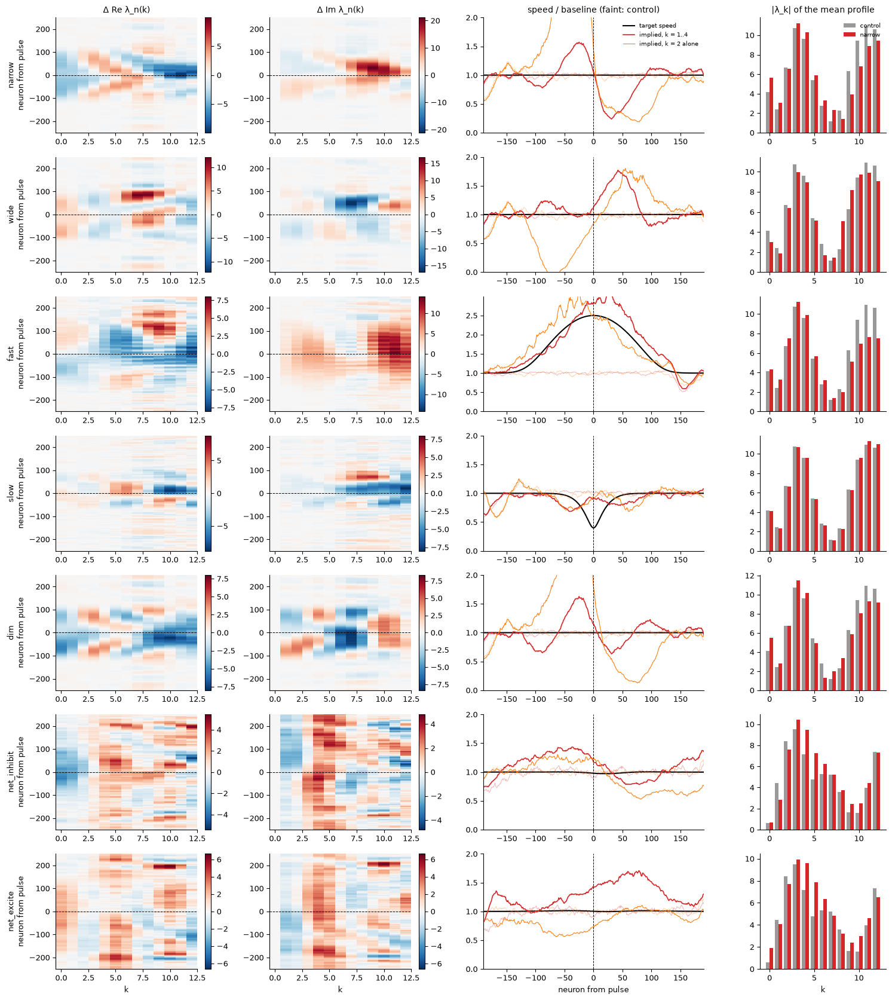

In [19]:
d = fig.load("I_harmonics")
F, axs = plt.subplots(len(pulsed), 4, figsize=(15, 2.4 * len(pulsed)), gridspec_kw={"width_ratios": [1, 1, 1.4, 0.8]})
for i, name in enumerate(pulsed):
    for j, key in enumerate(("dre", "dim")):
        im = pp.position_map(axs[i, j], d[f"{name}_{key}"], d["n"], d["k"], pulse=0.0)
        F.colorbar(im, ax=axs[i, j], fraction=0.05)
    ax = axs[i, 2]
    ax.plot(d["n"], d[f"{name}_vtrue"], "k", lw=1.5, label="target speed")
    for key, col, lab in (("fit", "C3", f"implied, k = {an['speed_harmonics'][0]}..{an['speed_harmonics'][-1]}"),
                          ("2", "C1", "implied, k = 2 alone")):
        ax.plot(d["n"], d[f"{name}_vc{key}"], color=col, lw=0.6, alpha=0.4)
        ax.plot(d["n"], d[f"{name}_v{key}"], color=col, lw=1.2 if key == "fit" else 0.8, label=lab)
    ax.set_ylim(0, max(2.0, 1.2 * np.nanmax(d[f"{name}_vtrue"])))
    ax.set_xlim(d["n"][inner_n][0], d["n"][inner_n][-1]); pp.mark_pulse(ax, 0.0)
    ax = axs[i, 3]
    ax.bar(d["k"] - 0.2, d[f"{name}_absc"], 0.4, color="0.6", label="control")
    ax.bar(d["k"] + 0.2, d[f"{name}_abs"], 0.4, color="C3", label=name)
    axs[i, 0].set_ylabel(f"{name}\nneuron from pulse")
axs[0, 0].set_title("Δ Re λ_n(k)"); axs[0, 1].set_title("Δ Im λ_n(k)")
axs[0, 2].set_title("speed / baseline (faint: control)"); axs[0, 2].legend(frameon=False, fontsize=7)
axs[0, 3].set_title("|λ_k| of the mean profile"); axs[0, 3].legend(frameon=False, fontsize=7)
for j, lab in enumerate(("k", "k", "neuron from pulse", "k")):
    axs[-1, j].set_xlabel(lab)
F.tight_layout()
fig.savefig("I_harmonics", F); plt.show()

## Panel J — how much the profile varies along the sequence, per offset d

For each offset d, the standard deviation across neurons of the realization-mean profile (interior neurons). Dotted:
the noise floor, the same statistic expected from realization noise alone for a translation-invariant matrix.
- **Pulsed and control:** where the pulsed curve rises above the control's, the pulse makes the connectivity
  heterogeneous along the sequence at that offset.
- **Paired difference** (pulsed − control, realization by realization): every condition uses the same seed, so run r
  of both shares J0 and noise, and the difference keeps only the pulse's effect.
- **Caveat:** the pairing holds only while the two runs draw the same noise at the same steps. A speed pulse changes
  the snippet's length and the network targets shift the update times, so for those conditions the noise decorrelates
  and the paired floor is high.

In [20]:
interior = np.nonzero(inner_n)[0]
out = {"d": dwin}
for name in pulsed:
    o = order(name)
    Pp, Pc = P[name][:, o], P[conds[name]["control"]][:, o]
    for key, X in (("p", Pp), ("c", Pc), ("diff", Pp - Pc)):
        v = npf.variance_along_sequence(npf.remove_self(dwin, X), interior)
        out[f"{name}_{key}_sd"], out[f"{name}_{key}_noise"] = np.sqrt(v["across"]), np.sqrt(v["noise"])
fig.save("J_variance", params={"edge": an["edge"]}, **out);

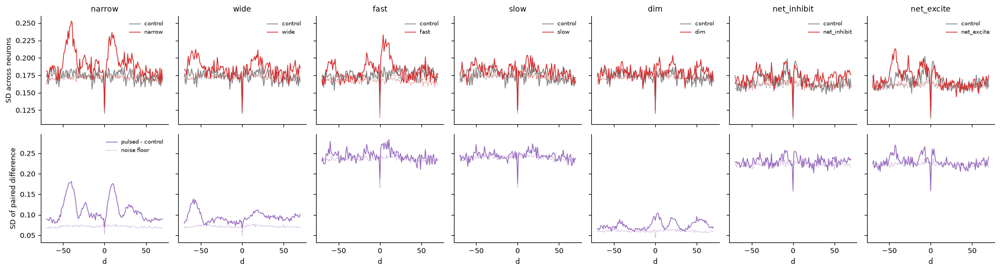

In [21]:
d = fig.load("J_variance")
F, axs = plt.subplots(2, len(pulsed), figsize=(2.6 * len(pulsed), 5), sharex=True, sharey="row")
for j, name in enumerate(pulsed):
    ax = axs[0, j]
    for key, col, lab in (("c", "0.5", "control"), ("p", "C3", name)):
        ax.plot(d["d"], d[f"{name}_{key}_sd"], color=col, lw=1, label=lab)
        ax.plot(d["d"], d[f"{name}_{key}_noise"], color=col, lw=0.8, ls=":")
    ax.set_title(name); ax.legend(frameon=False, fontsize=7)
    ax = axs[1, j]
    ax.plot(d["d"], d[f"{name}_diff_sd"], color="C4", lw=1, label="pulsed - control")
    ax.plot(d["d"], d[f"{name}_diff_noise"], color="C4", lw=0.8, ls=":", label="noise floor")
    ax.set_xlabel("d")
    if j == 0:
        ax.legend(frameon=False, fontsize=7)
axs[0, 0].set_ylabel("SD across neurons"); axs[1, 0].set_ylabel("SD of paired difference")
F.tight_layout()
fig.savefig("J_variance", F); plt.show()

## Panel K — what kind of change: stretch, gain, and the main shapes of change

- **Stretch and gain** (rows 1–2). Each neuron's profile (smoothed) is fitted as a stretched, scaled copy of the
  control's mean profile, p_n(d) ≈ a_n·ref(d/s_n).
  - s < 1: the lobes move toward d = 0. s > 1: they spread.
  - a: an overall gain.
  - Grey: the control's own neurons.
- **Main shapes of change** (rows 3–4). An SVD across interior neurons of the smoothed change (pulsed − control):
  - row 3: the change shapes over d, with the share of the total change each explains;
  - row 4: how strongly each neuron carries each shape along the sequence.

In [22]:
out = {"d": dwin, "n": nn}
for name in pulsed:
    o = order(name)
    sp_ = npf.smooth_neurons(npf.remove_self(dwin, P[name].mean(0)[o]), an["smooth"])
    sc_ = npf.smooth_neurons(npf.remove_self(dwin, P[conds[name]["control"]].mean(0)[o]), an["smooth"])
    ref = sc_[interior].mean(0)
    for key, X in (("p", sp_), ("c", sc_)):
        f = npf.dilation_fit(dwin, X, ref, min_r2=an["stretch_min_r2"])
        out[f"{name}_{key}_scale"], out[f"{name}_{key}_amp"], out[f"{name}_{key}_r2"] = f["scale"], f["amplitude"], f["r2"]
    m = npf.difference_modes((sp_ - sc_)[interior], 2)
    out[f"{name}_modes"], out[f"{name}_explained"] = m["modes"], m["explained"]
    out[f"{name}_scores"] = (sp_ - sc_) @ m["modes"].T  # every neuron, not only the interior
fig.save("K_stretch_modes", params={"modes": 2}, **out);

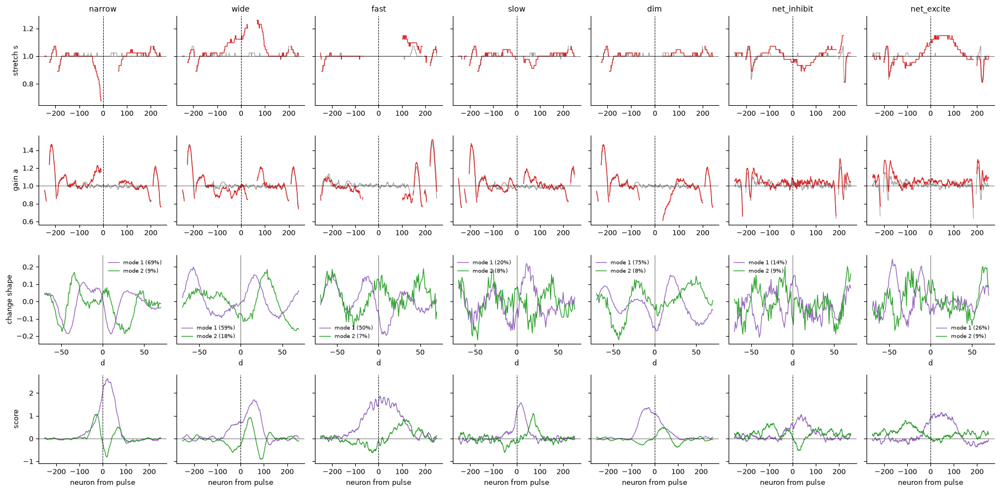

In [23]:
d = fig.load("K_stretch_modes")
F, axs = plt.subplots(4, len(pulsed), figsize=(2.6 * len(pulsed), 9), sharey="row")
for j, name in enumerate(pulsed):
    for i, (key, lab) in enumerate((("scale", "stretch s"), ("amp", "gain a"))):
        ax = axs[i, j]
        ax.plot(d["n"], d[f"{name}_c_{key}"], color="0.6", lw=0.8)
        ax.plot(d["n"], d[f"{name}_p_{key}"], color="C3", lw=1)
        ax.axhline(1.0, color="k", lw=0.4); pp.mark_pulse(ax, 0.0)
        if j == 0:
            ax.set_ylabel(lab)
    axs[0, j].set_title(name)
    for m, col in ((0, "C4"), (1, "C2")):
        axs[2, j].plot(d["d"], d[f"{name}_modes"][m], color=col, lw=1, label=f"mode {m + 1} ({100 * d[f'{name}_explained'][m]:.0f}%)")
        axs[3, j].plot(d["n"], d[f"{name}_scores"][:, m], color=col, lw=1)
    axs[2, j].axvline(0, color="k", lw=0.4); axs[2, j].legend(frameon=False, fontsize=7); axs[2, j].set_xlabel("d")
    axs[3, j].axhline(0, color="k", lw=0.4); pp.mark_pulse(axs[3, j], 0.0); axs[3, j].set_xlabel("neuron from pulse")
axs[2, 0].set_ylabel("change shape"); axs[3, 0].set_ylabel("score")
F.tight_layout()
fig.savefig("K_stretch_modes", F); plt.show()

## Panel L — interactive explorer

Choose a condition and slide through the sequence. The panels show that neuron's incoming and outgoing profiles
(mean ± SEM over realizations, averaged over ± `smooth`/2 neighbours) against the control, plus its local harmonic
spectrum. This needs a live kernel (`ipywidgets`); it is not rendered in the saved notebook.

In [24]:
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None
    print("ipywidgets not installed; skipped")
if widgets is not None:
    Pout = {name: npf.window(npf.local_profiles(W[name], "out"), an["d_max"])[1] for name in names}

    def show(condition, neuron, smooth):
        o, ctl = order(condition), conds[condition]["control"]
        idx = o[(N // 2 + neuron + np.arange(smooth) - smooth // 2) % N]
        F, axs = plt.subplots(1, 3, figsize=(14, 3.2))
        for ax, src, lab in ((axs[0], P, "incoming"), (axs[1], Pout, "outgoing")):
            for key, col in ((ctl, "0.5"), (condition, "C3")):
                x = npf.remove_self(dwin, src[key][:, idx].mean(1))
                m, s = x.mean(0), sem(x)
                ax.plot(dwin, m, color=col, label=key); ax.fill_between(dwin, m - s, m + s, color=col, alpha=0.3, lw=0)
            ax.axvline(0, color="k", lw=0.4); ax.set_title(f"{lab}, neuron {neuron:+d} from pulse"); ax.set_xlabel("d")
            ax.legend(frameon=False)
        for key, col in ((ctl, "0.5"), (condition, "C3")):
            l = lam[key][idx].mean(0)[ks]
            axs[2].plot(ks, l.real, "o-", color=col, ms=3, label=f"Re {key}")
            axs[2].plot(ks, l.imag, "s--", color=col, ms=3, label=f"Im {key}")
        axs[2].axhline(0, color="k", lw=0.4); axs[2].set_xlabel("k"); axs[2].set_title("local harmonics")
        axs[2].legend(frameon=False, fontsize=7)
        plt.show()

    widgets.interact(show, condition=widgets.Dropdown(options=pulsed, value=pulsed[0]),
                     neuron=widgets.IntSlider(value=0, min=-N // 2 + an["edge"], max=N // 2 - an["edge"], step=1,
                                              continuous_update=False),
                     smooth=widgets.IntSlider(value=an["smooth"], min=1, max=41, step=2, continuous_update=False));

interactive(children=(Dropdown(description='condition', options=('narrow', 'wide', 'fast', 'slow', 'dim', 'net…

## Panel M — summary and checks

For each pulsed condition and group, the change of each profile feature from control to pulsed (mean ± SEM over
realizations, incoming profiles). The *localized* check asks whether the pulse changes the *at* group's profile more
than the *before* and *after* groups' (L2 norm of the mean difference, self-weight excluded).

In [25]:
d = fig.load("F_groups"); B = fig.load("B_training"); I_ = fig.load("I_harmonics"); K_ = fig.load("K_stretch_modes")
rows, local = [], {}
for name in pulsed:
    norms = {}
    for g in gnames:
        p, c = d[f"in_{name}_p_{g}"], d[f"in_{name}_c_{g}"]
        sp, sc_ = npf.profile_summary(d["d"], p), npf.profile_summary(d["d"], c)
        delta = {f: sp[f] - sc_[f] for f in feats}
        rows.append((name, g, {f: (float(delta[f].mean()), float(sem(delta[f][:, None])[0])) for f in feats}))
        norms[g] = float(np.linalg.norm(npf.remove_self(d["d"], (p - c).mean(0))))
    local[name] = norms
print(f"{'condition':12s} {'group':7s} " + " ".join(f"{'d' + f:>18s}" for f in feats))
for name, g, v in rows:
    print(f"{name:12s} {g:7s} " + " ".join(f"{m:+8.3f} ± {s:6.3f}  " for m, s in (v[f] for f in feats)))
test_corr = {n: round(float(B[f"{n}_corr"][:, -tr["n_test"]:].mean()), 3) for n in names}
Wc = W[names[0]]
fig.checks([
    {"item": "every condition trains (test corr > 0.7)", "value": test_corr, "passed": min(test_corr.values()) > 0.7},
    {"item": "per-neuron profiles average to Braun's mean profile (max abs diff)",
     "value": float(np.abs(npf.local_profiles(Wc).mean(-2) - cv.profile_from_matrix(Wc)).max()),
     "passed": bool(np.allclose(npf.local_profiles(Wc).mean(-2), cv.profile_from_matrix(Wc)))},
    *[{"item": f"{n}: pulse effect localized at the pulse (|pulsed - control| per group)",
       "value": {g: round(v, 3) for g, v in local[n].items()},
       "passed": local[n]["at"] > max(v for g, v in local[n].items() if g != "at")} for n in pulsed],
    *[{"item": f"{n}: harmonics track the speed change (corr of the fitted implied speed with the target speed, interior)",
       "value": round(float(np.corrcoef(I_[f"{n}_vfit"][inner_n], I_[f"{n}_vtrue"][inner_n])[0, 1]), 3),
       "passed": float(np.corrcoef(I_[f"{n}_vfit"][inner_n], I_[f"{n}_vtrue"][inner_n])[0, 1]) > 0.7}
      for n in pulsed if conds[n]["pulse"].param == "gain"],
    *[{"item": f"{n}: share of the change in its first shape (mode 1)", "value": round(float(K_[f"{n}_explained"][0]), 3),
       "passed": None} for n in pulsed],
])

condition    group                dself              dpeak            dtrough         dasymmetry
narrow       before    +0.009 ±  0.002     +0.005 ±  0.001     +0.001 ±  0.002     -0.002 ±  0.001  
narrow       at        +0.186 ±  0.024     +0.066 ±  0.014     -0.054 ±  0.013     -0.213 ±  0.003  
narrow       after     +0.007 ±  0.004     +0.003 ±  0.004     +0.008 ±  0.009     -0.002 ±  0.001  
wide         before    -0.008 ±  0.003     +0.002 ±  0.003     +0.001 ±  0.001     +0.007 ±  0.002  
wide         at        -0.035 ±  0.007     +0.034 ±  0.003     +0.016 ±  0.017     -0.017 ±  0.002  
wide         after     +0.004 ±  0.006     +0.007 ±  0.006     +0.007 ±  0.006     -0.002 ±  0.002  
fast         before    +0.063 ±  0.042     -0.025 ±  0.029     -0.014 ±  0.013     -0.055 ±  0.007  
fast         at        -0.106 ±  0.021     -0.027 ±  0.025     +0.039 ±  0.012     -0.613 ±  0.006  
fast         after     +0.065 ±  0.046     +0.017 ±  0.025     -0.024 ±  0.016     -0.043 ±  0.

WindowsPath('C:/Users/max/Documents/phd-work/results/pulsed/data/pulsed_testbed/acceptance.json')